[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/07-llms-and-genai/notebooks/03-tokens-cost-and-local-models.ipynb)

# 03 - Tokens, cost, local models (Ollama) and choosing a model

**Goal:** count tokens with `tiktoken`, estimate the cost of an LLM feature, read the module's Excel cost calculator, understand how **Ollama** runs models locally (with an offline fallback when Ollama isn't installed), and pick a model with a simple decision guide.

**About prices:** prices change often, so this notebook uses **made-up example prices** that are clearly labelled. For real numbers, use the official pricing pages:
- OpenAI: https://openai.com/api/pricing/
- Anthropic: https://platform.claude.com/docs/en/about-claude/pricing
- Google Gemini: https://ai.google.dev/gemini-api/docs/pricing

## Setup

In [1]:
import importlib.util, subprocess, sys
# Install a package only if it is missing (Colab already has most of these).
def ensure(pkg, module=None):
    if importlib.util.find_spec(module or pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for pkg, mod in [("tiktoken", "tiktoken"), ("openpyxl", "openpyxl"), ("httpx", "httpx"), ("transformers", "transformers")]:
    ensure(pkg, mod)
import tiktoken, numpy as np, pandas as pd, matplotlib.pyplot as plt
enc = tiktoken.get_encoding("o200k_base")
pd.set_option("display.max_colwidth", 120)   # show long text in tables without cutting it off
print("ready")

ready


## 1. Counting tokens

`tiktoken` is exact for recent OpenAI models and a reasonable estimate for others (Anthropic and Gemini have their own tokenizers and `count_tokens` API calls, which need a key). A chat adds a few extra tokens per message for the role markers.

In [2]:
def count(text):
    return len(enc.encode(text))

def count_messages(messages, overhead=4):
    return sum(count(m["content"]) + overhead for m in messages)

system = "You are a helpful support agent for an online bakery in Hyderabad. Answer in under 80 words."
user = "Hi, my cake order #5512 was supposed to arrive at 4pm but it's 6pm now. Can you check?"
msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
print("system:", count(system), "tokens | user:", count(user), "tokens | whole request ~", count_messages(msgs))

system: 20 tokens | user: 27 tokens | whole request ~ 55


Rule-of-thumb check: about 4 characters per token for English. Let's compare the rule with the real count on a few texts.

In [3]:
texts = {
    "short English": "Please summarise this article in three bullet points.",
    "Python code": "def add(a, b):\n    return a + b\n\nprint(add(2, 3))",
    "JSON": '{"order_id": 5512, "status": "out_for_delivery", "eta_minutes": 25}',
    "Hindi": "कृपया इस लेख का तीन बिंदुओं में सारांश दें।",
}
pd.DataFrame([{"text": k, "chars": len(v), "rule_of_thumb (chars/4)": round(len(v) / 4), "real tokens": count(v)}
              for k, v in texts.items()])

,text,chars,rule_of_thumb (chars/4),real tokens
0,short English,53,13,10
1,Python code,49,12,20
2,JSON,67,17,23
3,Hindi,43,11,16


## 2. Estimating cost

Cost of one call = input tokens × input price + output tokens × output price (prices are per **1 million** tokens). The prices below are **invented for practice only**.

In [4]:
# !!! EXAMPLE PRICES - MADE UP FOR PRACTICE, NOT REAL. Fill in real ones from the official pages. !!!
EXAMPLE_PRICES = {               # (input $ per 1M tokens, output $ per 1M tokens)
    "example-small-model":  (0.20, 0.80),
    "example-medium-model": (1.00, 5.00),
    "example-large-model":  (5.00, 25.00),
}

def cost_per_request(n_in, n_out, prices):
    p_in, p_out = prices
    return n_in * p_in / 1e6 + n_out * p_out / 1e6

n_in, n_out = count_messages(msgs), 150
for name, prices in EXAMPLE_PRICES.items():
    one = cost_per_request(n_in, n_out, prices)
    print(f"{name:<22} per request ${one:.6f} | 1,000 req/day for 30 days: ${one * 1000 * 30:,.2f}")

example-small-model    per request $0.000131 | 1,000 req/day for 30 days: $3.93
example-medium-model   per request $0.000805 | 1,000 req/day for 30 days: $24.15
example-large-model    per request $0.004025 | 1,000 req/day for 30 days: $120.75


Plot monthly cost against traffic. Notice how the model choice matters more than almost anything else once traffic grows. Output tokens usually dominate because they cost more.

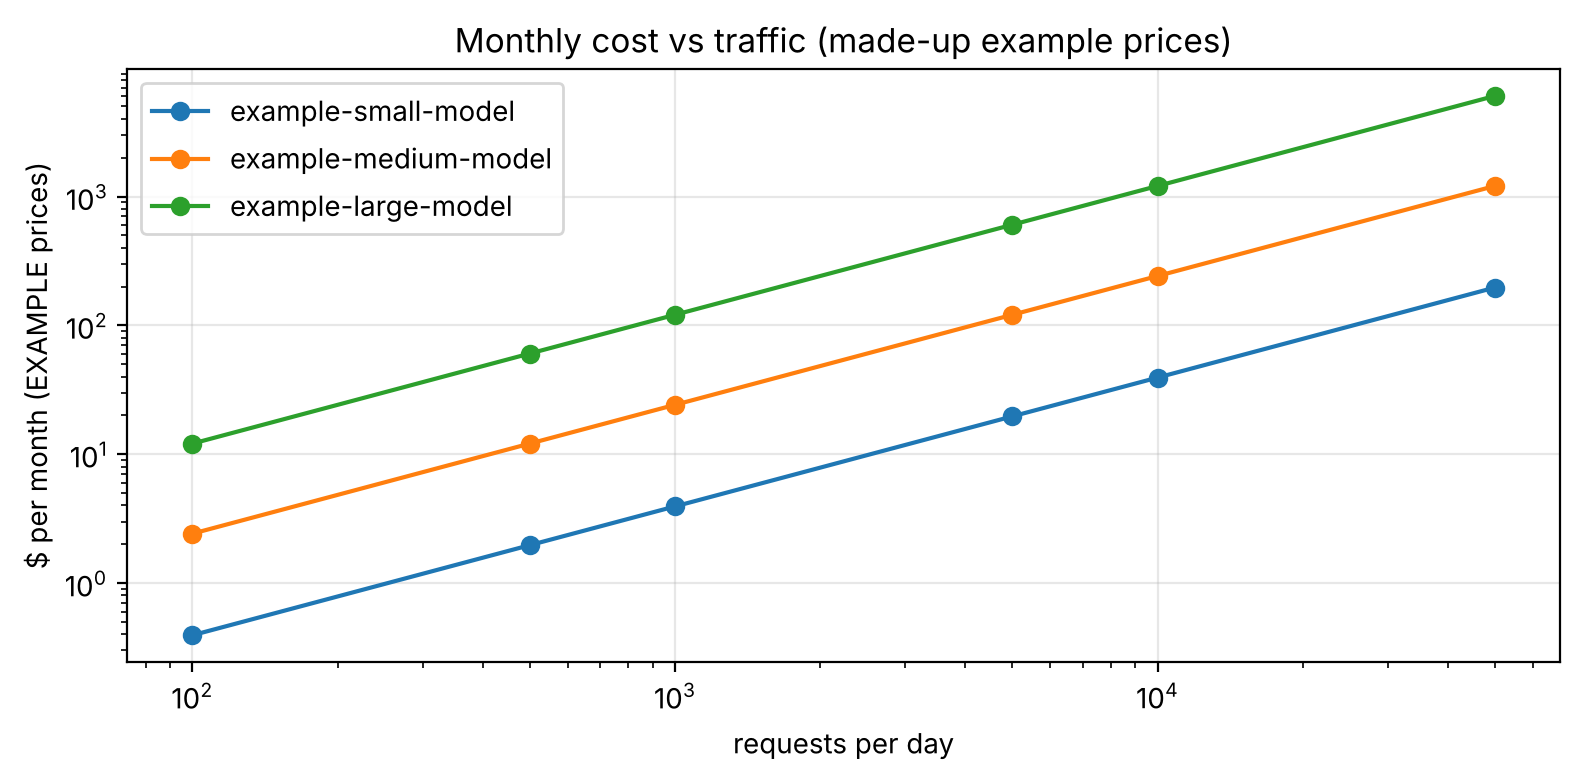

In [5]:
traffic = np.array([100, 500, 1000, 5000, 10000, 50000])
plt.figure(figsize=(8, 4))
for name, prices in EXAMPLE_PRICES.items():
    plt.plot(traffic, traffic * 30 * cost_per_request(n_in, n_out, prices), marker="o", label=name)
plt.xscale("log"); plt.yscale("log")
plt.xlabel("requests per day"); plt.ylabel("$ per month (EXAMPLE prices)")
plt.title("Monthly cost vs traffic (made-up example prices)"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. The Excel cost calculator

`excel/07-llm-cost-calculator.xlsx` does the same with **live formulas**. Yellow cells are inputs; prices are blank until you fill them in from the official pricing pages. We open it with `openpyxl` to look at the formulas. (If the file is not next to this notebook — e.g. on Colab — it is downloaded from the course repo.)

In [6]:
import pathlib, httpx, openpyxl
path = pathlib.Path("../excel/07-llm-cost-calculator.xlsx")
if not path.exists():
    url = "https://raw.githubusercontent.com/vvvvvivekkk/AI-Engineer/main/07-llms-and-genai/excel/07-llm-cost-calculator.xlsx"
    try:
        path = pathlib.Path("07-llm-cost-calculator.xlsx")
        path.write_bytes(httpx.get(url, timeout=30, follow_redirects=True).raise_for_status().content)
    except Exception as e:
        print("Could not download the workbook:", e); path = None
if path:
    wb = openpyxl.load_workbook(path)
    print("Sheets:", wb.sheetnames)
    ws = wb["Calculator"]
    for cell in ws[1]:
        print(f"{cell.column_letter}1 {cell.value!r:<32} row 2 -> {ws.cell(row=2, column=cell.column).value!r}")

Sheets: ['How to use', 'Prices', 'Calculator', 'Compare models', 'Token estimator']
A1 'Scenario'                       row 2 -> 'Support chatbot'
B1 'Model label (from Prices)'      row 2 -> 'EXAMPLE-ONLY'
C1 'Requests per day'               row 2 -> 1000
D1 'Avg input tokens'               row 2 -> 600
E1 'Avg output tokens'              row 2 -> 200
F1 'Days per month'                 row 2 -> 30
G1 'Input $ per 1M'                 row 2 -> '=IFERROR(VLOOKUP(B2,Prices!$A$2:$E$30,4,FALSE),0)'
H1 'Output $ per 1M'                row 2 -> '=IFERROR(VLOOKUP(B2,Prices!$A$2:$E$30,5,FALSE),0)'
I1 'Cost per request $'             row 2 -> '=(D2*G2+E2*H2)/1000000'
J1 'Cost per day $'                 row 2 -> '=I2*C2'
K1 'Cost per month $'               row 2 -> '=J2*F2'
L1 'Cost per year $'                row 2 -> '=K2*12'


## 4. Log real usage

After every real API call, record the **usage** numbers the provider returns (they are what you are billed for). A tiny log like the one below — appended to a CSV in a real app — lets you check the estimate against reality. Here the records are simulated.

In [7]:
log = pd.DataFrame([
    {"time": "09:00", "model": "example-small-model", "input_tokens": 61, "output_tokens": 120},
    {"time": "09:01", "model": "example-small-model", "input_tokens": 64, "output_tokens": 98},
    {"time": "09:03", "model": "example-medium-model", "input_tokens": 950, "output_tokens": 410},
])
log["cost_$"] = [cost_per_request(r.input_tokens, r.output_tokens, EXAMPLE_PRICES[r.model]) for r in log.itertuples()]
print(log)
print("Total (example prices): $", round(log["cost_$"].sum(), 6))

    time                 model  input_tokens  output_tokens    cost_$
0  09:00   example-small-model            61            120  0.000108
1  09:01   example-small-model            64             98  0.000091
2  09:03  example-medium-model           950            410  0.003000
Total (example prices): $ 0.003199


## 5. Local models with Ollama

**Ollama** runs open-weight models on your own computer and serves them at `http://localhost:11434`. It cannot be installed on the course server, so this cell **checks** whether an Ollama server is reachable. If yes, it calls the REST API; if not, it falls back to SmolLM2 through `transformers` — same idea, different engine.

On your own laptop: install from https://ollama.com, run `ollama pull llama3.2:1b`, and re-run this cell. Full scripts: `code/ollama_rest.py`, `code/ollama_client.py`, `code/ollama_commands.sh`.

In [8]:
import os
OLLAMA = os.getenv("OLLAMA_HOST", "http://localhost:11434")
OLLAMA_MODEL = os.getenv("OLLAMA_MODEL", "llama3.2:1b")
messages = [{"role": "system", "content": "Answer in one sentence."},
            {"role": "user", "content": "What is quantisation in LLMs?"}]

def ollama_available():
    try:
        return httpx.get(OLLAMA, timeout=2).status_code == 200
    except httpx.HTTPError:
        return False

if ollama_available():
    r = httpx.post(f"{OLLAMA}/api/chat", json={"model": OLLAMA_MODEL, "messages": messages, "stream": False}, timeout=300)
    print("[Ollama]", r.json()["message"]["content"])
else:
    print("Ollama not reachable here -> offline fallback with transformers (SmolLM2-135M)")
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M-Instruct")
    model = AutoModelForCausalLM.from_pretrained("HuggingFaceTB/SmolLM2-135M-Instruct", dtype=torch.float32)
    inputs = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=50, do_sample=False)
    print("[fallback]", tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))

Ollama not reachable here -> offline fallback with transformers (SmolLM2-135M)


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  50%|████▉     | 135/272 [00:00<00:00, 1347.85it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1564.49it/s]

[fallback] In the context of the LLLM (Long Short-Term Memory) model, quantisation refers to the process of assigning numerical values to the input features, such as the number of features, the number of classes, or the number of features in


The same Ollama server through three different doors (shown, not run here):

```python
# 1) official Python client:  pip install ollama
import ollama
resp = ollama.chat(model="llama3.2:1b", messages=messages)
print(resp.message.content)

# 2) OpenAI SDK pointed at Ollama's OpenAI-compatible endpoint
from openai import OpenAI
client = OpenAI(base_url="http://localhost:11434/v1", api_key="ollama")   # key is ignored but required
print(client.chat.completions.create(model="llama3.2:1b", messages=messages).choices[0].message.content)

# 3) terminal:  ollama run llama3.2:1b "What is quantisation?"
```

**How much memory does a local model need?** Roughly: parameters × bits per parameter ÷ 8, plus some overhead for the context. Let's compute it.

In [9]:
def approx_memory_gb(params_billion, bits=4, overhead=1.2):
    return params_billion * 1e9 * bits / 8 / 1e9 * overhead

for size in [0.135, 1, 3, 8, 70]:
    print(f"{size:>6}B params: 16-bit ~{approx_memory_gb(size, 16):6.1f} GB | 4-bit ~{approx_memory_gb(size, 4):5.1f} GB")

 0.135B params: 16-bit ~   0.3 GB | 4-bit ~  0.1 GB
     1B params: 16-bit ~   2.4 GB | 4-bit ~  0.6 GB
     3B params: 16-bit ~   7.2 GB | 4-bit ~  1.8 GB
     8B params: 16-bit ~  19.2 GB | 4-bit ~  4.8 GB
    70B params: 16-bit ~ 168.0 GB | 4-bit ~ 42.0 GB


## 6. Choosing a model

A tiny decision helper that encodes the guide from `concepts.md`. It is deliberately simple; real decisions come from testing on your own examples.

In [10]:
def recommend(private_data, difficulty, input_tokens, monthly_budget_usd):
    if private_data:
        return "Open-weight model run locally (Ollama) or on your own server"
    if input_tokens > 100_000:
        return "A model with a very large context window - check provider model pages; or use RAG (Module 09)"
    if difficulty == "simple":
        return "Smallest/cheapest tier of a major provider; test it first"
    if monthly_budget_usd < 20:
        return "Free tier (e.g. Gemini) or local model; upgrade only if quality fails"
    return "Provider's top tier for hard tasks; measure cost with the calculator"

scenarios = [
    ("Hospital notes summariser", True, "hard", 3000, 500),
    ("Tag 50k support tickets / day", False, "simple", 300, 300),
    ("Analyse a 400-page contract", False, "hard", 250_000, 1000),
    ("Student homework helper prototype", False, "hard", 1000, 0),
    ("Coding assistant for a team", False, "hard", 8000, 2000),
]
pd.DataFrame([{"scenario": s, "recommendation": recommend(*args)} for s, *args in scenarios])

,scenario,recommendation
0,Hospital notes summariser,Open-weight model run locally (Ollama) or on your own server
1,Tag 50k support tickets / day,Smallest/cheapest tier of a major provider; test it first
2,Analyse a 400-page contract,A model with a very large context window - check provider model pages; or use RAG (Module 09)
3,Student homework helper prototype,Free tier (e.g. Gemini) or local model; upgrade only if quality fails
4,Coding assistant for a team,Provider's top tier for hard tasks; measure cost with the calculator


## Try it yourself
1. Open the Excel calculator, fill in today's real prices for two models from the official pages, and compare with the Python numbers.
2. Change `n_out` from 150 to 600. By how much does monthly cost grow for each example model?
3. Add a "needs image input" option to `recommend()`.
4. On your own computer, install Ollama and run `code/ollama_rest.py`. Compare speed with SmolLM2.